# 10 · Adsorption and fixed beds

A porous solid can pull a component out of a fluid onto its surface: activated carbon for organics, zeolites
for water and CO$_2$, silica for chromatography. Adsorption runs in cycles - a bed loads until the solute
breaks through, then is regenerated - so its design is about isotherms (capacity) and breakthrough curves
(how sharply the bed fills). This notebook fits isotherms to the course data, sizes a batch adsorber,
predicts breakthrough with the constant-pattern model, and scales a laboratory column to a plant bed.

**What you will learn**
- fit Langmuir and Freundlich isotherms
- size a batch adsorber
- predict fixed-bed breakthrough with the constant-pattern model
- analyse breakthrough curves and scale up with the LUB method

**Before you start:** notebook 06  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engsep import adsorption as ad
from engsep import datasets
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Isotherms from batch data

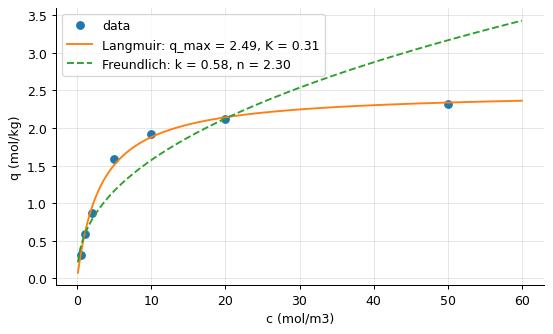

Phenol on activated carbon: batch isotherm points (Langmuir, 4 % noise).


In [2]:
d = pd.read_csv(datasets.path("isotherm_phenol_carbon.csv"), comment="#")
lf, ff = ad.fit_langmuir(d.c_mol_m3, d.q_mol_kg), ad.fit_freundlich(d.c_mol_m3, d.q_mol_kg)
c = np.linspace(0.1, 60, 200)
fig, ax = plt.subplots(); ax.plot(d.c_mol_m3, d.q_mol_kg, "o", label="data"); ax.plot(c, ad.langmuir(c, lf["q_max"], lf["K"]), label=f"Langmuir: q_max = {lf['q_max']:.2f}, K = {lf['K']:.2f}"); ax.plot(c, ad.freundlich(c, ff["k"], ff["n"]), "--", label=f"Freundlich: k = {ff['k']:.2f}, n = {ff['n']:.2f}")
ax.set(xlabel="c (mol/m3)", ylabel="q (mol/kg)"); ax.legend(); plt.show()
print(datasets.describe("isotherm_phenol_carbon.csv"))

Langmuir's isotherm saturates at a monolayer; Freundlich's keeps rising as a power law. Over the measured
range both fit - the data cannot tell them apart - but they extrapolate differently, and the Langmuir
capacity $q_{max}$ is what a bed's saturation loading depends on. A *favourable* isotherm (concave, like
these) is what makes fixed-bed adsorption sharp.

## A batch adsorber

In [3]:
iso = lambda cc: ad.langmuir(cc, lf["q_max"], lf["K"])
for m_carbon in (5.0, 20.0, 50.0):
    b = ad.batch_adsorber(c0=20.0, V=1.0, m=m_carbon, isotherm=iso)
    print(f"{m_carbon:4.0f} kg carbon per m3 of 20 mol/m3 phenol: equilibrium c = {b['c']:.2f} mol/m3, removal {b['removal']:.1%}, loading {b['q']:.2f} mol/kg")

   5 kg carbon per m3 of 20 mol/m3 phenol: equilibrium c = 10.49 mol/m3, removal 47.5%, loading 1.90 mol/kg
  20 kg carbon per m3 of 20 mol/m3 phenol: equilibrium c = 1.86 mol/m3, removal 90.7%, loading 0.91 mol/kg
  50 kg carbon per m3 of 20 mol/m3 phenol: equilibrium c = 0.60 mol/m3, removal 97.0%, loading 0.39 mol/kg


A batch adsorber equilibrates along a straight operating line ($V(c_0 - c) = mq$) that meets the isotherm:
more carbon, lower residual, but at a falling loading - the last percent of removal wastes capacity, which
is why batch adsorption is for small volumes and the fixed bed for everything else.

## The fixed bed: the ideal wave and the real breakthrough

a 1 m bed at 1 cm/s: the concentration wave moves at 106.0 um/s and the ideal breakthrough time is 2.62 h


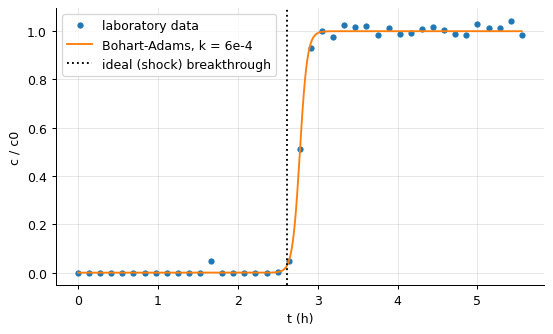

In [4]:
q0, c0, rho_b, eps, L, u = float(iso(10.0)), 10.0, 500.0, 0.4, 1.0, 0.01
t_star = ad.stoichiometric_time(q0, c0, rho_b, eps, L, u)
print(f"a 1 m bed at 1 cm/s: the concentration wave moves at {ad.wave_velocity(q0, c0, rho_b, eps, u)*1e6:.1f} um/s and the ideal breakthrough time is {t_star/3600:.2f} h")
b = pd.read_csv(datasets.path("breakthrough_curve.csv"), comment="#")
t = np.linspace(0, 20000, 400)
fig, ax = plt.subplots(); ax.plot(b.t_s / 3600, b.c_over_c0, "o", ms=4, label="laboratory data"); ax.plot(t / 3600, ad.bohart_adams(t, c0, 2.0, rho_b, L, u, 6e-4), label="Bohart-Adams, k = 6e-4"); ax.axvline(t_star / 3600, color="k", ls=":", label="ideal (shock) breakthrough")
ax.set(xlabel="t (h)", ylabel="c / c0"); ax.legend(); plt.show()

With no mass-transfer resistance the bed would fill as a sharp front (a shock wave) arriving at the
stoichiometric time. Real beds show an S-shaped breakthrough curve spread by mass transfer; for a
favourable isotherm the spread reaches a constant pattern that travels unchanged - the Bohart-Adams curve
through the data, apart from one sample that a careful eye rejects.

## Analysing the curve: used bed and LUB

In [5]:
mask = np.ones(len(b), bool); mask[12] = False                     # the contaminated sample
an = ad.breakthrough_analysis(b.t_s[mask], b.c_over_c0[mask], c_break=0.05, c_exhaust=0.95)
print(f"breakthrough at {an['t_break']/3600:.2f} h, exhaustion at {an['t_exhaust']/3600:.2f} h, stoichiometric time {an['t_stoich']/3600:.2f} h")
print(f"fraction of the bed used at breakthrough {an['used_fraction']:.2f}; length of unused bed {an['LUB_fraction'] * L:.2f} m")
for L_new in (2.0, 4.0):
    s = ad.lub_scale_up(an["LUB_fraction"] * L, L, an["t_break"], L_new)
    print(f"a {L_new:.0f} m bed of the same packing: breakthrough after {s['t_break_new']/3600:.1f} h, using {s['used_fraction_new']:.0%} of its capacity")

breakthrough at 2.64 h, exhaustion at 2.96 h, stoichiometric time 2.79 h
fraction of the bed used at breakthrough 0.95; length of unused bed 0.05 m
a 2 m bed of the same packing: breakthrough after 5.4 h, using 97% of its capacity
a 4 m bed of the same packing: breakthrough after 11.0 h, using 99% of its capacity


At breakthrough (5 % of the feed concentration leaving) the bed is only partly used: the mass-transfer zone
occupies the unused length, and that length is a property of the packing and flow, not of the bed's length.
That is the LUB scale-up: a longer plant bed wastes the same absolute length, so its fractional use improves.
A one-metre laboratory column sizes a four-metre plant bed with one number.

## Pressure-swing adsorption: a cycle balance

In [6]:
q_high, q_low = ad.langmuir(6.0 * 40.0, 3.0, 0.02), ad.langmuir(1.0 * 40.0, 3.0, 0.02)          # loadings at 6 bar and 1 bar (c in mol/m3 ~ 40 x P/bar for an ideal gas at 300 K)
cyc = ad.psa_cycle(q_high, q_low, rho_b=650.0, V_bed=2.0, y_feed=0.2, c_feed=0.2 * 240.0)
print(f"working capacity per cycle {cyc['working_capacity_mol']:.0f} mol; feed processed per cycle {cyc['feed_volume_per_cycle']:.1f} m3 at 6 bar")

working capacity per cycle 1494 mol; feed processed per cycle 31.1 m3 at 6 bar


Pressure-swing adsorption regenerates the bed by depressurising instead of heating: the working capacity is
the difference between the loadings at the two pressures, and two beds alternate every few minutes. Air
separation on zeolites (nitrogen adsorbs more strongly) and hydrogen purification run this way; the isotherm's
curvature between the two pressures is the whole design.

## Inside the algorithm: the stoichiometric time

In [7]:
print("by hand:", L * (eps + rho_b * q0 / c0) / u, "s; library:", ad.stoichiometric_time(q0, c0, rho_b, eps, L, u))

by hand: 9437.013236766636 s; library: 9437.013236766636


## Exercises
1. The phenol bed is fed at 5 mol/m3 instead of 10. Recompute the ideal breakthrough time and the Bohart-Adams curve (same k). Why does a lower feed concentration give a *longer* time but a *broader* curve, and how does the LUB change?
2. Design a two-bed system: one bed adsorbs while the other regenerates for 4 h. For the 10 mol/m3 feed at 1 cm/s, what bed length gives a breakthrough time of at least 4 h using the LUB from the laboratory column?
3. **Implement it yourself:** compute the stoichiometric time of the laboratory breakthrough curve as the area above the curve (trapezoidal rule) and compare with `adsorption.breakthrough_analysis`.